<a href="https://colab.research.google.com/github/aerofa45/Heston-Modeling-using-PINN/blob/main/PINN_Heston_Standalone_Colab_Trial_BGFS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINN-Heston (Standalone Google Colab Version)
This notebook contains the complete implementation of:
- PINN training for Heston model
- Feller condition enforcement
- LS benchmarking
- Implied volatility surface fitting
- Synthetic scenario evaluation
- Ablation studies
- Unit tests

In [ ]:
# Install required libraries
!pip install yfinance QuantLib-Python py_vollib matplotlib scikit-learn pyyaml


  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.1/20.1 MB 61.5 MB/s eta 0:00:00
  Created wheel for py_vollib: filename=py_vollib-1.0.1-py3-none-any.whl size=62833 sha256=2d753ac99931c99a92d26fcde75ce1b0837d9711fb72d112e69d9efe64b4fe47
  Stored in directory: /root/.cache/pip/wheels/c0/5c/8f/1ed590a10a2cca3cbfa7a7caa29fb5d729b3e1f819bfda4b5e
  Created wheel for py_lets_be_rational: filename=py_lets_be_rational-1.0.1-py3-none-any.whl size=24451 sha256=7f2140130f09c252173702d89013622d6dd2590541aae9f62f2c7cad812f77e4
  Stored in directory: /root/.cache/pip/wheels/d9/20/b1/018f644bacb669d5cd6af600fe09ee0729ae5d75875a9f3043
Successfully built py_vollib py_lets_be_rational


In [ ]:
# Install and enable ipywidgets in Colab
!pip install ipywidgets
from google.colab import output
output.enable_custom_widget_manager()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 21.9 MB/s eta 0:00:00


# Settings and Configs

In [ ]:
import torch, numpy as np, random, yaml, matplotlib.pyplot as plt, torch.nn as nn, torch.optim as optim
from datetime import datetime
import yfinance as yf

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.use_deterministic_algorithms(True)




# PINN Heston Model

In [ ]:
import torch.nn as nn

class PINN_Heston(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=128):
        super().__init__()
        self.hidden = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )
        self.kappa = nn.Parameter(torch.abs(torch.randn(1) * 2.0))  # Absolute value to ensure positivity
        self.theta = nn.Parameter(torch.abs(torch.randn(1) * 0.04))
        self.sigma = nn.Parameter(torch.abs(torch.randn(1) * 0.5))
        self.rho = nn.Parameter(torch.tensor(-0.7))  # Negative correlation is fine
        self.v0 = nn.Parameter(torch.abs(torch.randn(1) * 0.04))


    def forward(self, x):
        return self.hidden(x).squeeze(-1)


In [ ]:
def heston_pde_residual(model, S, v, t, r):
    S.requires_grad_(True)
    v.requires_grad_(True)
    t.requires_grad_(True)
    inputs = torch.cat([S, v, t], dim=1)
    V = model(inputs)

    grads = torch.autograd.grad(V, inputs, grad_outputs=torch.ones_like(V), create_graph=True)[0]
    V_S, V_v, V_t = grads[:, 0:1], grads[:, 1:2], grads[:, 2:3]
    V_SS = torch.autograd.grad(V_S, S, grad_outputs=torch.ones_like(V_S), create_graph=True)[0]
    V_vv = torch.autograd.grad(V_v, v, grad_outputs=torch.ones_like(V_v), create_graph=True)[0]
    V_Sv = torch.autograd.grad(V_S, v, grad_outputs=torch.ones_like(V_S), create_graph=True)[0]

    kappa, theta, sigma, rho = model.kappa, model.theta, model.sigma, model.rho
    res = (V_t + 0.5 * v * S ** 2 * V_SS + rho * sigma * v * S * V_Sv +
           0.5 * sigma ** 2 * v * V_vv + r * S * V_S +
           kappa * (theta - v) * V_v - r * V.unsqueeze(1))

    return res.squeeze()



# Check Feller Function

In [ ]:


def apply_pois_ge_scheme(kappa, theta, sigma):
    # Poisson-conditioned Gamma Expansion

    # Calculate concentration (shape) and rate (scale) parameters
    concentration = kappa * theta / sigma  # This should be positive
    rate = sigma / (kappa * theta)  # This should also be positive

    # Convert concentration and rate to tensors to avoid TypeError
    concentration = torch.tensor(concentration, dtype=torch.float32)
    rate = torch.tensor(rate, dtype=torch.float32)

    # Clamp the concentration and rate to ensure they are positive
    concentration = torch.clamp(concentration, min=1e-5)  # Ensure positive concentration
    rate = torch.clamp(rate, min=1e-5)  # Ensure positive rate

    # Sample from Gamma distribution with corrected parameters
    variance = torch.abs(torch.distributions.Gamma(concentration, rate).sample())

    return variance


In [ ]:
def feller_condition_penalty(kappa, theta, sigma):
    lhs = 2 * kappa * theta  # Left-hand side of the Feller condition
    rhs = sigma**2  # Right-hand side of the Feller condition

    lhs_tensor = torch.tensor(lhs, dtype=torch.float32)
    rhs_tensor = torch.tensor(rhs, dtype=torch.float32)

    if lhs_tensor >= rhs_tensor:
        penalty = 0.0  # Feller condition satisfied, no penalty
    else:
        # Apply POIS–GE or POIS–TD scheme if Feller condition fails
        penalty = apply_pois_ge_scheme(kappa, theta, sigma)  # OR apply_pois_td_scheme(kappa, theta, sigma)

        # Clipping the penalty to avoid extreme updates
        penalty = torch.clamp(penalty, min=0, max=10)  # Clip to reasonable range

    return penalty


In [ ]:
def check_feller_condition(kappa, theta, sigma):
    lhs = 2 * kappa * theta
    rhs = sigma**2
    satisfied = lhs >= rhs
    print(f"Feller condition: {'True' if satisfied else 'False'} (2kθ={lhs:.4f} vs σ²={rhs:.4f})")  # Check if condition is satisfied
    return satisfied  # Return status and values for logging


In [ ]:
from sklearn.metrics import mean_squared_error

def price_mse(pred_prices, true_prices):
    return mean_squared_error(true_prices, pred_prices)

def iv_mse(pred_iv, true_iv):
    return mean_squared_error(true_iv, pred_iv)


**Synthetic Data**

In [ ]:
import datetime
from QuantLib import (
    UnitedStates, Actual365Fixed, Date, Following, SimpleQuote, QuoteHandle, FlatForward,
    YieldTermStructureHandle, HestonProcess, HestonModel, AnalyticHestonEngine,
    PlainVanillaPayoff, EuropeanExercise, VanillaOption, Settings, Days
)

def generate_synthetic_data(n=100, stress=None, noise_std=0.0):
    S = np.random.uniform(80, 120, n)
    K = np.random.uniform(80, 120, n)
    T = np.random.uniform(0.05, 0.5, n)

    params = {
        'kappa': 2.0,
        'theta': 0.04,
        'sigma': 0.5,
        'rho': -0.7,
        'v0': 0.04
    }

    if stress:
        params.update(stress)

    calendar = UnitedStates(UnitedStates.NYSE)
    day_count = Actual365Fixed()
    flat_ts = YieldTermStructureHandle(FlatForward(0, calendar, 0.05, day_count))
    div_ts = YieldTermStructureHandle(FlatForward(0, calendar, 0.0, day_count))

    prices = []
    for i in range(n):
        spot = S[i]
        today = datetime.date.today()
        ql_today = Date(today.day, today.month, today.year)
        Settings.instance().evaluationDate = calendar.adjust(ql_today, Following)

        spot_handle = QuoteHandle(SimpleQuote(spot))
        process = HestonProcess(flat_ts, div_ts, spot_handle,
                                params['v0'], params['kappa'], params['theta'],
                                params['sigma'], params['rho'])
        model = HestonModel(process)
        engine = AnalyticHestonEngine(model)
        payoff = PlainVanillaPayoff(1, K[i])  # 1 = Call
        maturity_date = calendar.advance(Settings.instance().evaluationDate, int(T[i] * 365), Days)
        option = VanillaOption(payoff, EuropeanExercise(maturity_date))
        option.setPricingEngine(engine)
        price = option.NPV()
        prices.append(price)

    prices = np.array(prices)
    if noise_std > 0:
        prices += np.random.normal(0, noise_std, size=prices.shape)

    inputs = torch.tensor(np.stack([S, np.ones_like(S) * params['v0'], T], axis=1), dtype=torch.float32)
    targets = torch.tensor(prices, dtype=torch.float32).unsqueeze(-1)
    return inputs, targets, params


In [ ]:
def load_market_data(ticker='AAPL', lookback_days='1mo', option_range=(0.95, 1.05)):
    ticker_data = yf.Ticker(ticker)
    stock_data = ticker_data.history(period=lookback_days, interval="1d")
    S_hist = stock_data['Close'].values
    S = torch.tensor(S_hist, dtype=torch.float32)
    log_returns = torch.log(S[1:] / S[:-1])
    v = log_returns.pow(2)

    today = datetime.datetime.now().date()
    expirations = ticker_data.options
    target_exp = next(
        (exp for exp in expirations if 10 <= (datetime.datetime.strptime(exp, "%Y-%m-%d").date() - today).days <= 30),
        None
    )
    if target_exp is None:
        raise ValueError("No suitable expiration found in 10–30 day range.")

    calls = ticker_data.option_chain(target_exp).calls
    spot = S[-1].item()
    mask = (calls['strike'] > option_range[0] * spot) & (calls['strike'] < option_range[1] * spot)
    calls = calls[mask]

    if len(calls) == 0:
        raise ValueError("No near-the-money options available in given range.")

    S_opts = torch.tensor([spot] * len(calls), dtype=torch.float32).view(-1, 1)
    v_opts = v[-1].repeat(len(calls)).view(-1, 1)
    t_opts = torch.tensor(
        [(datetime.datetime.strptime(target_exp, "%Y-%m-%d").date() - today).days / 365.0] * len(calls),
        dtype=torch.float32
    ).view(-1, 1)

    inputs = torch.cat([S_opts, v_opts, t_opts], dim=1)
    targets = torch.tensor(((calls['bid'] + calls['ask']) / 2).values, dtype=torch.float32).view(-1, 1)
    strikes = calls['strike'].values  # ✅ extract real strikes

    # Normalize
    inputs[:, 0] /= S.max()
    inputs[:, 1] /= v.max()
    inputs[:, 2] /= inputs[:, 2].max()

    return inputs, targets, S.max(), v.max(), strikes


In [ ]:
# Coolocation_points
# Updated Collocation Points (in original format)
colloc_points = (
    torch.FloatTensor(2000, 1).uniform_(80, 120).requires_grad_(),  # Spot Price S
    torch.FloatTensor(2000, 1).uniform_(80, 120).requires_grad_(),  # Strike Price K
    torch.FloatTensor(2000, 1).uniform_(0.1, 2.0).requires_grad_(), # Time to Maturity T
)

# Config Points (Updated for better training stability)
config = {
    'learning_rate': 1e-3,
    'lambda_data': 1.0,
    'lambda_pde': 1e-2,
    'lambda_feller': 7,  # Feller penalty weight
    'r': 0.05,
    'max_epochs': 20000
}


In [ ]:
USE_SYNTHETIC = True  # Set to False to use real market data

if USE_SYNTHETIC:
        print("🧪 Using synthetic data...")
        inputs, targets, true_params = generate_synthetic_data(n=100)
        K = np.random.uniform(80, 120, len(inputs))  # synthetic strikes

else:
        print("📈 Using real market data...")
        inputs, targets, _, _, K = load_market_data(ticker='SPY', lookback_days='1mo', option_range=(0.9, 1.1))
        true_params = None  # Not available for real data

🧪 Using synthetic data...


In [ ]:
import torch
import torch.optim as optim
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.optim.lr_scheduler import ReduceLROnPlateau
import numpy as np
from sklearn.model_selection import KFold
import time

def train(model, inputs_market, V_market, colloc_points, config):
    optimizer = optim.AdamW(model.parameters(), lr=config['learning_rate'], weight_decay=1e-5)
    scheduler = ReduceLROnPlateau(optimizer, 'min', patience=20000, factor=0.5)
    feller_optimizer = optim.AdamW([model.kappa, model.theta, model.sigma], lr=config['lambda_feller'], weight_decay=1e-5)

    mse = nn.MSELoss()
    S_c, v_c, t_c = colloc_points
    loss_history = []
    param_history = {k: [] for k in ['kappa', 'theta', 'sigma', 'rho', 'v0']}

    for epoch in range(config['max_epochs']):
        model.train()
        optimizer.zero_grad()
        feller_optimizer.zero_grad()

        # Forward pass and data loss
        pred = model(inputs_market)
        loss_data = mse(pred.unsqueeze(1), V_market)

        # Residual loss (PDE loss)
        res = heston_pde_residual(model, S_c, v_c, t_c, config['r'])
        loss_pde = mse(res, torch.zeros_like(res))

        # Feller condition penalty
        penalty_feller = feller_condition_penalty(model.kappa.item(), model.theta.item(), model.sigma.item())

        # Total loss combining data loss, PDE loss, and Feller penalty
        total_loss = config['lambda_data'] * loss_data + config['lambda_pde'] * loss_pde + config['lambda_feller'] * penalty_feller


        total_loss.backward()

        # Step the optimizer for the model parameters
        optimizer.step()

        # Optionally, update the Feller penalty parameters
        feller_optimizer.step()

        # Step the scheduler based on the total loss
        scheduler.step(total_loss)

        # Record history for parameters
        loss_history.append(total_loss.item())
        param_history['kappa'].append(model.kappa.item())
        param_history['theta'].append(model.theta.item())
        param_history['sigma'].append(model.sigma.item())
        param_history['rho'].append(model.rho.item())
        param_history['v0'].append(model.v0.item())

        if epoch % 100 == 0:
            print(f"Epoch {epoch}: Loss={total_loss.item():.6f}")
            check_feller_condition(model.kappa.item(), model.theta.item(), model.sigma.item())

    return loss_history, param_history



def cross_validate(model_class, inputs, targets, colloc_points, config, k=5):

    # Standardize the inputs
    scaler = StandardScaler()
    inputs_standardized = scaler.fit_transform(inputs)

    # Convert inputs to torch.Tensor
    inputs_standardized = torch.from_numpy(inputs_standardized).float()

    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    mse_values = []
    param_history = {k: [] for k in ['kappa', 'theta', 'sigma', 'rho', 'v0']}  # For storing parameter evolution
    fold_mse_values = []  # Store MSE for each fold for plotting

    for fold, (train_idx, val_idx) in enumerate(kf.split(inputs_standardized)):
        print(f"Fold {fold+1}/{k}")
        # Start timer
        start_time = time.time()

        # Split data into training and validation sets
        train_inputs, val_inputs = inputs_standardized[train_idx], inputs_standardized[val_idx]
        train_targets, val_targets = targets[train_idx], targets[val_idx]

        # Initialize the model
        model = model_class()

        # Train the model
        loss_history, param_history = train(model, train_inputs, train_targets, colloc_points, config)

        # Evaluate on validation set
        with torch.no_grad():
            preds = model(val_inputs).numpy()

        # Compute MSE for this fold
        mse = price_mse(preds, val_targets.numpy())
        mse_values.append(mse)
        fold_mse_values.append(mse)
        print(f"Validation MSE for fold {fold+1}: {mse:.6f}")

        # End timer
        end_time = time.time()
        print(f"Time taken for fold {fold+1}: {end_time - start_time:.2f} seconds")

    # Print average performance across all folds
    avg_mse = np.mean(mse_values)
    print(f"Average MSE across {k} folds: {avg_mse:.6f}")

    # Visualization of MSE for each fold
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(fold_mse_values)+1), fold_mse_values, marker='o', label="MSE per fold")
    plt.axhline(y=avg_mse, color='r', linestyle='--', label=f"Average MSE: {avg_mse:.6f}")
    plt.xlabel("Fold")
    plt.ylabel("Mean Squared Error (MSE)")
    plt.title(f"K-fold Cross-validation: {k}-fold")
    plt.legend()
    plt.grid(True)
    plt.show()

    return avg_mse, param_history

# Sample inputs and targets assumed to be numpy arrays or torch tensors
# Assuming `inputs`, `targets`, and `colloc_points` are already defined
print("🔁 Running Cross-Validation")
cross_validate(PINN_Heston, inputs, targets, colloc_points, config, k=5)


🔁 Running Cross-Validation
Fold 1/5
Epoch 0: Loss=31454.265625
Feller condition: False (2kθ=-122.9257 vs σ²=46.1551)
Epoch 100: Loss=210.653839
Feller condition: False (2kθ=1478.3365 vs σ²=6047.6241)
Epoch 200: Loss=201.629196
Feller condition: False (2kθ=1492.6466 vs σ²=5961.5194)
Epoch 300: Loss=193.579086
Feller condition: False (2kθ=1480.9208 vs σ²=5877.6733)
Epoch 400: Loss=185.761063
Feller condition: False (2kθ=1473.6072 vs σ²=5795.0632)
Epoch 500: Loss=177.943588
Feller condition: False (2kθ=1467.5959 vs σ²=5713.6745)
Epoch 600: Loss=170.200104
Feller condition: False (2kθ=1458.5933 vs σ²=5633.5611)
Epoch 700: Loss=162.768402
Feller condition: False (2kθ=1446.7120 vs σ²=5554.7935)
Epoch 800: Loss=155.837280
Feller condition: False (2kθ=1430.0236 vs σ²=5477.3054)
Epoch 900: Loss=149.468704
Feller condition: False (2kθ=1406.3939 vs σ²=5401.0859)
Epoch 1000: Loss=143.635315
Feller condition: False (2kθ=1377.7123 vs σ²=5326.0286)
Epoch 1100: Loss=138.273941
Feller condition: False 

In [ ]:


# ✅ Check Feller condition for trained PINN model
print("\n Checking Feller condition (PINN):")
check_feller_condition(
        model.kappa.item(),
        model.theta.item(),
        model.sigma.item()
    )

Final Training
Epoch 0: Loss=44575.054688
Feller condition: False (2kθ=0.1716 vs σ²=2.7378)
Epoch 100: Loss=177.410034
Feller condition: False (2kθ=0.0604 vs σ²=2.5700)
Epoch 200: Loss=162.816193
Feller condition: False (2kθ=0.0605 vs σ²=2.5699)
Epoch 300: Loss=149.558319
Feller condition: False (2kθ=0.0608 vs σ²=2.5697)
Epoch 400: Loss=138.065170
Feller condition: False (2kθ=0.0613 vs σ²=2.5696)
Epoch 500: Loss=128.854065
Feller condition: False (2kθ=0.0618 vs σ²=2.5694)
Epoch 600: Loss=121.533783
Feller condition: False (2kθ=0.0624 vs σ²=2.5693)
Epoch 700: Loss=115.956795
Feller condition: False (2kθ=0.0629 vs σ²=2.5691)
Epoch 800: Loss=111.875160
Feller condition: False (2kθ=0.0634 vs σ²=2.5690)
Epoch 900: Loss=108.931396
Feller condition: False (2kθ=0.0640 vs σ²=2.5688)
Epoch 1000: Loss=106.863098
Feller condition: False (2kθ=0.0644 vs σ²=2.5686)
Epoch 1100: Loss=105.452827
Feller condition: False (2kθ=0.0649 vs σ²=2.5685)
Epoch 1200: Loss=104.507141
Feller condition: False (2kθ=0.

False

## 📊 True vs Learned Parameters on Synthetic Data

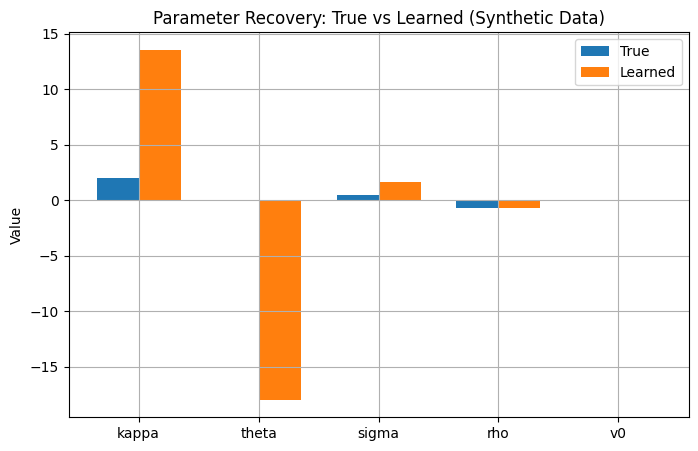

In [ ]:
def param_recovery_plot(true_params, learned_model):
    labels = ['kappa', 'theta', 'sigma', 'rho', 'v0']
    true_vals = [true_params[l] for l in labels]
    learned_vals = [getattr(learned_model, l).item() for l in labels]

    x = np.arange(len(labels))
    width = 0.35

    plt.figure(figsize=(8, 5))
    plt.bar(x - width/2, true_vals, width, label='True')
    plt.bar(x + width/2, learned_vals, width, label='Learned')
    plt.xticks(x, labels)
    plt.ylabel("Value")
    plt.title("Parameter Recovery: True vs Learned (Synthetic Data)")
    plt.legend()
    plt.grid(True)
    plt.show()



if USE_SYNTHETIC:
  param_recovery_plot(true_params, model)


## 📊 Error Distribution Plots (Price Residuals)

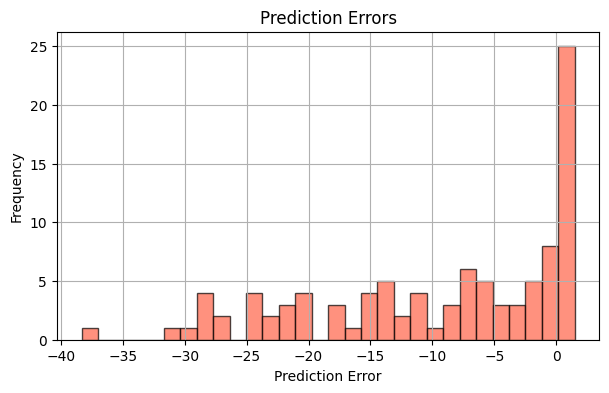

In [ ]:
def plot_error_distribution(true, pred, title="Prediction Errors"):
    errors = pred.flatten() - true.flatten()
    plt.figure(figsize=(7, 4))
    plt.hist(errors, bins=30, alpha=0.7, color='tomato', edgecolor='black')
    plt.title(title)
    plt.xlabel("Prediction Error")
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.show()


# 📉 Error distribution
with torch.no_grad():
  preds = model(inputs).numpy()
  plot_error_distribution(targets.numpy(), preds)


Implied Volatility Graphs

In [ ]:
from py_vollib.black_scholes.implied_volatility import implied_volatility
import numpy as np

def compute_implied_vol(price, S, K, T, r, option_type='c'):
    # Implied vol only makes sense if price is non-negative and T > 0
    if price < 1e-6 or T <= 0 or S <= 0 or K <= 0:
        return np.nan
    try:
        return implied_volatility(price, S, K, T, r, option_type)
    except Exception:
        return np.nan

def compute_iv_surface(prices, S_list, K_list, T_list, r):
    # Clean up prices before computing
    prices = np.clip(prices, 1e-6, None)
    return np.array([
        compute_implied_vol(p, S, K, T, r)
        for p, S, K, T in zip(prices, S_list, K_list, T_list)
    ])


K = np.linspace(80, 120, 20)  # 20 strike prices
T = np.linspace(0.1, 2.0, 20)  # 20 maturities
K_grid, T_grid = np.meshgrid(K, T)


S_val = 100  # or some average/typical spot price
r_val = 0.05

model_inputs = []
for t, k in zip(T_grid.ravel(), K_grid.ravel()):
  model_inputs.append([S_val, k, t])



model_inputs = torch.tensor(model_inputs, dtype=torch.float32)



# Predict option prices
with torch.no_grad():
    pred_prices = model(model_inputs).numpy()
pred_prices = pred_prices.reshape(T_grid.shape)


# Compute robust implied vol surface
iv_surface = compute_iv_surface(
    pred_prices.ravel(),
    [S_val] * len(pred_prices.ravel()),  # Repeat S for all options
    K_grid.ravel(),
    T_grid.ravel(),
    r_val
).reshape(T_grid.shape)



# Report NaN issues if any
print(f"NaNs in IV Surface: {np.isnan(iv_surface).sum()} out of {len(iv_surface)}")


NaNs in IV Surface: 245 out of 20


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


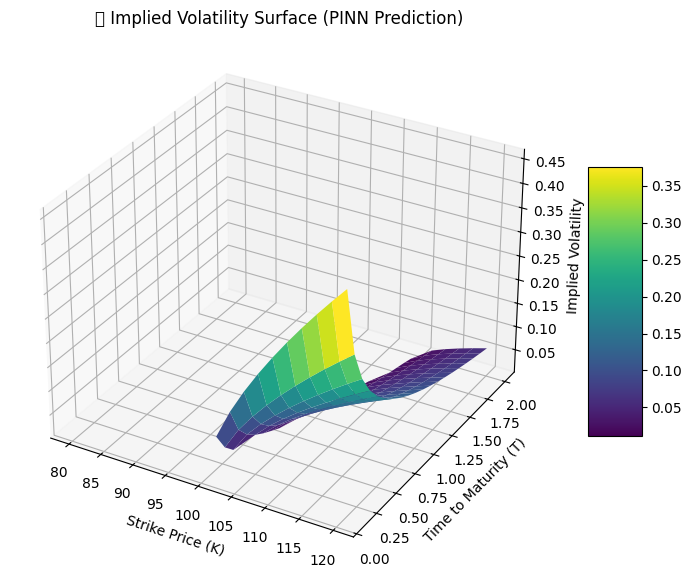

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_iv_surface_3d(K_grid, T_grid, iv_surface, title="Implied Volatility Surface"):
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    # Plot the surface
    surf = ax.plot_surface(K_grid, T_grid, iv_surface, cmap='viridis', edgecolor='none')

    ax.set_xlabel("Strike Price (K)")
    ax.set_ylabel("Time to Maturity (T)")
    ax.set_zlabel("Implied Volatility")
    ax.set_title(title)
    fig.colorbar(surf, shrink=0.5, aspect=5)
    plt.show()
plot_iv_surface_3d(K_grid, T_grid, iv_surface, title="📈 Implied Volatility Surface (PINN Prediction)")


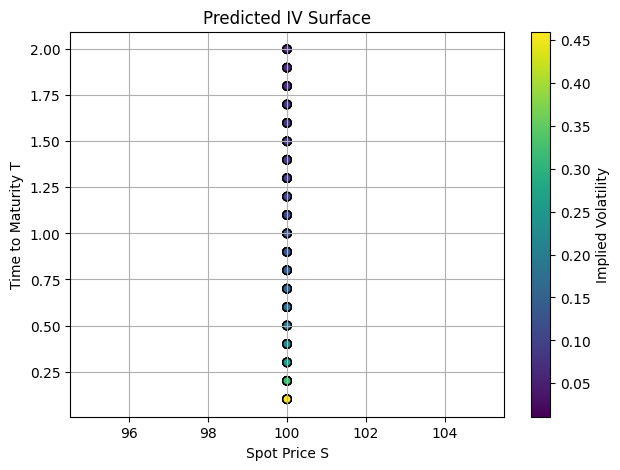

In [ ]:
def fallback_iv_plot(S_val, T_grid, iv_surface, title):
    T_flat = T_grid.ravel()
    iv_flat = iv_surface.ravel()
    S_flat = np.full_like(T_flat, S_val)  # same spot price for all points

    plt.figure(figsize=(7, 5))
    plt.scatter(S_flat, T_flat, c=iv_flat, cmap='viridis', edgecolor='k')
    plt.xlabel("Spot Price S")
    plt.ylabel("Time to Maturity T")
    plt.colorbar(label="Implied Volatility")
    plt.title(title)
    plt.grid(True)
    plt.show()

fallback_iv_plot(S_val, T_grid, iv_surface, "Predicted IV Surface")





## 📈 Training Diagnostics (Loss Curves)

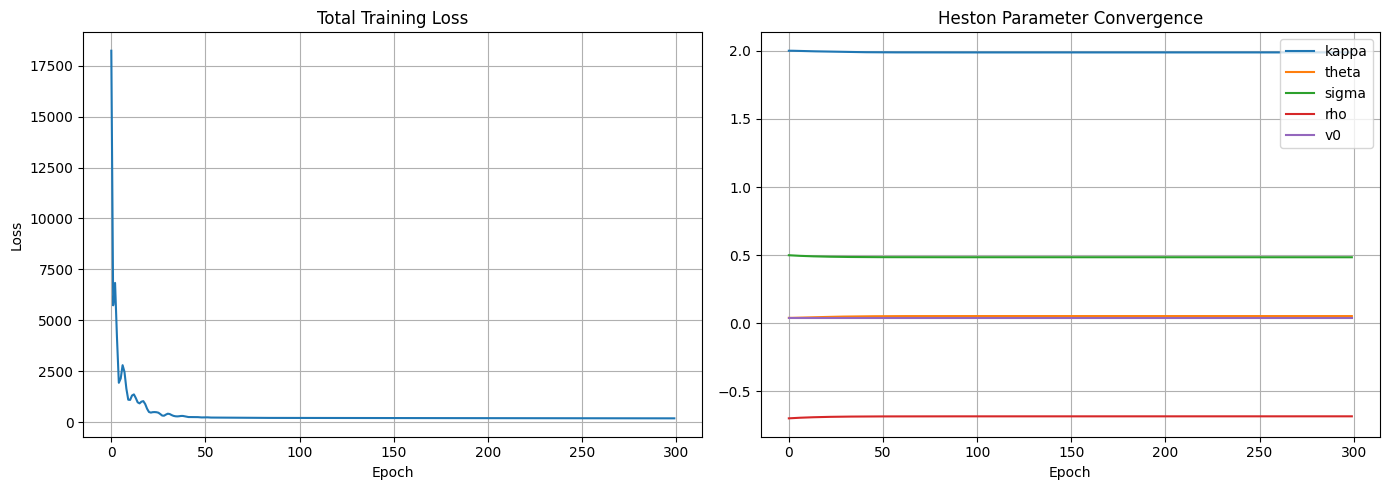

In [ ]:
def plot_training_diagnostics(loss_history, param_history):
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))

    # Loss curve
    axs[0].plot(loss_history)
    axs[0].set_title("Total Training Loss")
    axs[0].set_xlabel("Epoch")
    axs[0].set_ylabel("Loss")
    axs[0].grid(True)

    # Parameter convergence
    for k, v in param_history.items():
        axs[1].plot(v, label=k)
    axs[1].set_title("Heston Parameter Convergence")
    axs[1].set_xlabel("Epoch")
    axs[1].legend()
    axs[1].grid(True)

    plt.tight_layout()
    plt.show()

#Training diagnostics
plot_training_diagnostics(loss_history, param_history)





## 📉 Least Squares Benchmarking (Heston Closed-Form)

In [ ]:
from scipy.optimize import minimize
import numpy as np
from QuantLib import *

def heston_price(S, K, T, r, kappa, theta, sigma, rho, v0):
    calendar = UnitedStates(UnitedStates.GovernmentBond)
    day_count = Actual365Fixed()
    spot_handle = QuoteHandle(SimpleQuote(float(S)))
    flat_ts = YieldTermStructureHandle(FlatForward(0, calendar, r, day_count))
    div_ts = YieldTermStructureHandle(FlatForward(0, calendar, 0.0, day_count))
    process = HestonProcess(flat_ts, div_ts, spot_handle, v0, kappa, theta, sigma, rho)
    model = HestonModel(process)
    engine = AnalyticHestonEngine(model)

    payoff = PlainVanillaPayoff(Option.Call, float(K))
    from QuantLib import Period, Days

    days_to_maturity = int(T * 365)
    maturity_date = calendar.advance(Settings.instance().evaluationDate, Period(days_to_maturity, Days))
    option = VanillaOption(payoff, EuropeanExercise(maturity_date))
    option.setPricingEngine(engine)
    return option.NPV()

def ls_objective(params, S_list, K_list, T_list, r, market_prices):
    kappa, theta, sigma, rho, v0 = params
    model_prices = np.array([
        heston_price(S, K, T, r, kappa, theta, sigma, rho, v0)
        for S, K, T in zip(S_list, K_list, T_list)
    ])
    # Ensure that model_prices and market_prices have the same shape
    if model_prices.shape != market_prices.shape:
        raise ValueError(f"Shape mismatch: model_prices shape = {model_prices.shape}, market_prices shape = {market_prices.shape}")

    return np.mean((model_prices - market_prices) ** 2)

def run_ls_calibration(S_list, K_list, T_list, r, market_prices):
    init_params = [2.0, 0.04, 0.5, -0.7, 0.04]
    bounds = [(0.01, 10), (0.01, 1), (0.01, 5), (-0.99, 0.99), (0.001, 1)]
    result = minimize(ls_objective, init_params,
                      args=(S_list, K_list, T_list, r, market_prices),
                      bounds=bounds)
    print("LS Calibrated Params:", result.x)
    return result.x

# ⚖️ Least Squares Calibration (Real or Synthetic)
print("🔧 Running Least Squares Calibration")
S = inputs[:, 0].numpy()  # Spot prices (first column)
K = inputs[:, 1].numpy()  # Strike prices (second column)
T = inputs[:, 2].numpy()  # Time to maturity (third column)
market_prices = targets.numpy().flatten()  # Flatten the market prices array

# Ensure all inputs have the same length
if len(S) != len(market_prices):
    raise ValueError(f"Shape mismatch: S_list length = {len(S)}, market_prices length = {len(market_prices)}")

# Run Least Squares Calibration
ls_params = run_ls_calibration(S, K, T, config['r'], market_prices)
print("✅ Least Squares Calibrated Params:", ls_params)

# ✅ Check Feller condition for LS-calibrated model
print("\n🔎 Checking Feller condition (LS):")
check_feller_condition(*ls_params[:3])  # kappa, theta, sigma


🔧 Running Least Squares Calibration
LS Calibrated Params: [ 2.    0.04  0.5  -0.7   0.04]
✅ Least Squares Calibrated Params: [ 2.    0.04  0.5  -0.7   0.04]

🔎 Checking Feller condition (LS):
Feller condition: False (2kθ=0.1600 vs σ²=0.2500)


np.False_

Main Run:

In [ ]:
import ipywidgets as widgets
from IPython.display import display

scenario_options = {
    "Default": {},
    "High Volatility (σ↑)": {"stress": {"sigma": 1.0}},
    "Low Mean Reversion (κ↓)": {"stress": {"kappa": 0.5}},
    "Extreme Correlation (ρ≈-1)": {"stress": {"rho": -0.99}},
    "Very High Long-run Variance (θ↑)": {"stress": {"theta": 0.2}},
    "Noisy Market (σ_noise)": {"noise_std": 2.0}
}

def run_stress_test(scenario):
    config = {
        'learning_rate': 1e-3,
        'lambda_data': 1.0,
        'lambda_pde': 1e-3,
        'r': 0.05,
        'max_epochs': 500
    }
    set_seed(42)
    kwargs = scenario_options.get(scenario, {})
    inputs, targets, _ = generate_synthetic_data(n=100, **kwargs)
    colloc = (torch.rand(2000, 1, requires_grad=True),
              torch.rand(2000, 1, requires_grad=True),
              torch.rand(2000, 1, requires_grad=True))
    model = PINN_Heston()
    train(model, inputs, targets, colloc, config)
    with torch.no_grad():
        preds = model(inputs).numpy()
    mse = price_mse(preds, targets.numpy())
    print(f"{scenario} → MSE: {mse:.6f}")

scenario_dropdown = widgets.Dropdown(options=list(scenario_options.keys()), description='Scenario:')
run_button = widgets.Button(description="Run Stress Test")

def on_run_clicked(b):
    run_stress_test(scenario_dropdown.value)

run_button.on_click(on_run_clicked)
display(scenario_dropdown, run_button)


Dropdown(description='Scenario:', options=('Default', 'High Volatility (σ↑)', 'Low Mean Reversion (κ↓)', 'Extr…

Button(description='Run Stress Test', style=ButtonStyle())

Epoch 0: Loss=171.775772, Feller Penalty=0.090000
Feller condition: False (2kθ=0.1600 vs σ²=0.2500)
Epoch 100: Loss=94.012367, Feller Penalty=0.258490
Feller condition: False (2kθ=-0.0949 vs σ²=0.1635)
Epoch 200: Loss=87.636421, Feller Penalty=0.000000
Feller condition: True (2kθ=0.1601 vs σ²=0.0998)
Epoch 300: Loss=46.853325, Feller Penalty=0.000000
Feller condition: True (2kθ=0.9705 vs σ²=0.0163)
Epoch 400: Loss=41.846527, Feller Penalty=0.000000
Feller condition: True (2kθ=1.1407 vs σ²=0.0014)
Default → MSE: 40.967819
Epoch 0: Loss=172.519211, Feller Penalty=0.090000
Feller condition: False (2kθ=0.1600 vs σ²=0.2500)
Epoch 100: Loss=97.472641, Feller Penalty=0.255406
Feller condition: False (2kθ=-0.0912 vs σ²=0.1642)
Epoch 200: Loss=90.405792, Feller Penalty=0.037749
Feller condition: False (2kθ=0.0618 vs σ²=0.0996)
Epoch 300: Loss=49.587631, Feller Penalty=0.000000
Feller condition: True (2kθ=0.8836 vs σ²=0.0174)
Epoch 400: Loss=44.580105, Feller Penalty=0.000000
Feller condition: T

In [ ]:
def run_ablation_study(param_name, values):
    config = {
        'learning_rate': 1e-3,
        'lambda_data': 1.0,
        'lambda_pde': 1e-3,
        'r': 0.05,
        'max_epochs': 500
    }
    set_seed(42)
    inputs, targets, _ = generate_synthetic_data(n=100)
    colloc = (torch.rand(2000, 1, requires_grad=True),
              torch.rand(2000, 1, requires_grad=True),
              torch.rand(2000, 1, requires_grad=True))

    results = []
    for val in values:
        cfg = config.copy()
        cfg[param_name] = val
        model = PINN_Heston()
        train(model, inputs, targets, colloc, cfg)
        with torch.no_grad():
            preds = model(inputs).numpy()
        mse = price_mse(preds, targets.numpy())
        results.append((val, mse))
        print(f"{param_name} = {val} → MSE: {mse:.6f}")

    x, y = zip(*results)
    plt.figure(figsize=(8, 5))
    plt.plot(x, y, marker='o')
    plt.title(f"Ablation Study: {param_name}")
    plt.xlabel(param_name)
    plt.ylabel("Price MSE")
    plt.grid(True)
    plt.show()


Dropdown(description='Param:', options=('lambda_pde', 'learning_rate'), value='lambda_pde')

Button(description='Run Ablation', style=ButtonStyle())

Epoch 0: Loss=171.775772, Feller Penalty=0.090000
Feller condition: False (2kθ=0.1600 vs σ²=0.2500)
Epoch 100: Loss=94.019279, Feller Penalty=0.265353
Feller condition: False (2kθ=-0.1004 vs σ²=0.1649)
Epoch 200: Loss=87.344238, Feller Penalty=0.000000
Feller condition: True (2kθ=0.1603 vs σ²=0.0988)
Epoch 300: Loss=46.615952, Feller Penalty=0.000000
Feller condition: True (2kθ=0.9670 vs σ²=0.0167)
Epoch 400: Loss=41.867115, Feller Penalty=0.000000
Feller condition: True (2kθ=1.1428 vs σ²=0.0015)
lambda_pde = 0.0001 → MSE: 41.022572
Epoch 0: Loss=169.507172, Feller Penalty=0.090000
Feller condition: False (2kθ=0.1600 vs σ²=0.2500)
Epoch 100: Loss=93.736870, Feller Penalty=0.088508
Feller condition: False (2kθ=0.1286 vs σ²=0.2171)
Epoch 200: Loss=83.234245, Feller Penalty=0.000000
Feller condition: True (2kθ=0.2584 vs σ²=0.1433)
Epoch 300: Loss=45.348499, Feller Penalty=0.000000
Feller condition: True (2kθ=0.9371 vs σ²=0.0464)
Epoch 400: Loss=41.588161, Feller Penalty=0.000000
Feller co

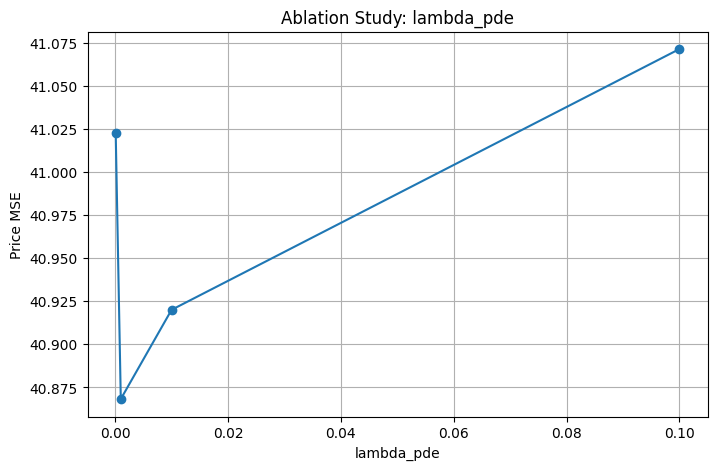

Epoch 0: Loss=171.775772, Feller Penalty=0.090000
Feller condition: False (2kθ=0.1600 vs σ²=0.2500)
Epoch 100: Loss=112.249557, Feller Penalty=0.087094
Feller condition: False (2kθ=0.1586 vs σ²=0.2456)
Epoch 200: Loss=99.522530, Feller Penalty=0.091288
Feller condition: False (2kθ=0.1409 vs σ²=0.2322)
Epoch 300: Loss=95.665413, Feller Penalty=0.109463
Feller condition: False (2kθ=0.1092 vs σ²=0.2186)
Epoch 400: Loss=94.337852, Feller Penalty=0.143224
Feller condition: False (2kθ=0.0643 vs σ²=0.2076)
learning_rate = 0.0001 → MSE: 93.705208
Epoch 0: Loss=169.507172, Feller Penalty=0.090000
Feller condition: False (2kθ=0.1600 vs σ²=0.2500)
Epoch 100: Loss=93.724350, Feller Penalty=0.000000
Feller condition: True (2kθ=0.2508 vs σ²=0.2481)
Epoch 200: Loss=92.733864, Feller Penalty=0.000000
Feller condition: True (2kθ=0.2563 vs σ²=0.2144)
Epoch 300: Loss=85.282402, Feller Penalty=0.000000
Feller condition: True (2kθ=0.3761 vs σ²=0.1611)
Epoch 400: Loss=62.962284, Feller Penalty=0.000000
Fell

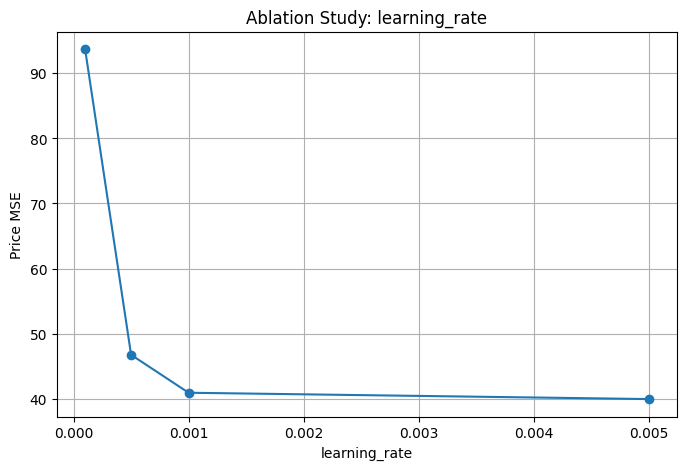

Epoch 0: Loss=171.775772, Feller Penalty=0.090000
Feller condition: False (2kθ=0.1600 vs σ²=0.2500)
Epoch 100: Loss=112.249557, Feller Penalty=0.087094
Feller condition: False (2kθ=0.1586 vs σ²=0.2456)
Epoch 200: Loss=99.522530, Feller Penalty=0.091288
Feller condition: False (2kθ=0.1409 vs σ²=0.2322)
Epoch 300: Loss=95.665413, Feller Penalty=0.109463
Feller condition: False (2kθ=0.1092 vs σ²=0.2186)
Epoch 400: Loss=94.337852, Feller Penalty=0.143224
Feller condition: False (2kθ=0.0643 vs σ²=0.2076)
learning_rate = 0.0001 → MSE: 93.705208
Epoch 0: Loss=169.507172, Feller Penalty=0.090000
Feller condition: False (2kθ=0.1600 vs σ²=0.2500)
Epoch 100: Loss=93.724350, Feller Penalty=0.000000
Feller condition: True (2kθ=0.2508 vs σ²=0.2481)
Epoch 200: Loss=92.733864, Feller Penalty=0.000000
Feller condition: True (2kθ=0.2563 vs σ²=0.2144)
Epoch 300: Loss=85.282402, Feller Penalty=0.000000
Feller condition: True (2kθ=0.3761 vs σ²=0.1611)
Epoch 400: Loss=62.962284, Feller Penalty=0.000000
Fell

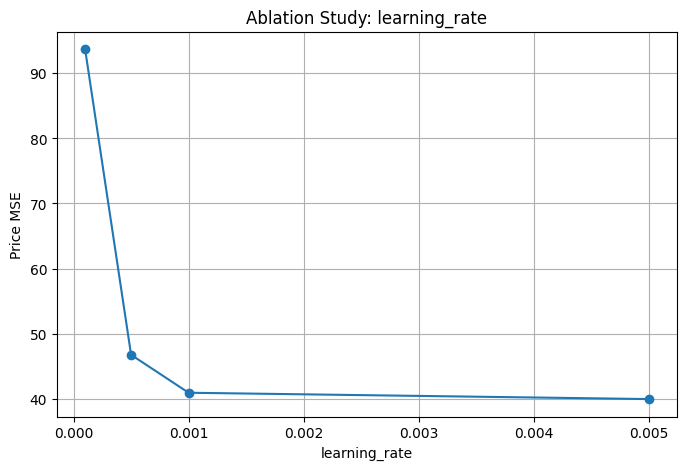

In [ ]:
param_dropdown = widgets.Dropdown(options=["lambda_pde", "learning_rate"], description='Param:')
value_ranges = {
    "lambda_pde": [1e-4, 1e-3, 1e-2, 1e-1],
    "learning_rate": [1e-4, 5e-4, 1e-3, 5e-3]
}

ablation_button = widgets.Button(description="Run Ablation")

def on_ablation_click(b):
    param = param_dropdown.value
    run_ablation_study(param, value_ranges[param])

ablation_button.on_click(on_ablation_click)
display(param_dropdown, ablation_button)


# Unit Testing

In [ ]:
def test_model_output_shape():
    model = PINN_Heston()
    x = torch.rand(10, 3)
    y = model(x)
    assert y.shape == (10,), "Output shape mismatch"

def test_pde_residual():
    model = PINN_Heston()
    S = torch.rand(10, 1, requires_grad=True)
    v = torch.rand(10, 1, requires_grad=True)
    t = torch.rand(10, 1, requires_grad=True)
    r = 0.05
    res = heston_pde_residual(model, S, v, t, r)
    assert res.shape == (10,), "Residual shape mismatch"

test_model_output_shape()
test_pde_residual()
print(" Unit tests passed!")

 Unit tests passed!
